# 02 – WaterWise AI Hattı: Veri Doğrulama, EDA, Model ve Değerlendirme

Bu notebook `01_data_exploration.ipynb` çalışmasının devamıdır. Tüm hesaplar `src/` modüllerinde yapılır; burada sonuçlar incelenir. Hattı baştan üretmek için:

```
venv\Scripts\python.exe -m src.run_pipeline
```

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
from src import config
from src.data_preprocessing import load_raw
pd.set_option('display.max_columns', None)

## 1. Ölçüm birimi doğrulaması

`value` toplamı README'deki 3271 m³ ile örtüşür; en küçük adım 0.001 (= sayaçların 1 L çözünürlüğü); `aggregated_value` sensörün kümülatif sayaç endeksidir ve ardışık farkı `value`'ya eşittir.

In [2]:
raw = load_raw()
print('Σvalue =', round(raw['value'].sum(), 3), '(README: ~3271 m³)')
print('En küçük değer:', raw['value'].min(), '→ 1 L')
s = raw.sort_values(['sensor_id', 'timestamp']).drop_duplicates()
d = s.groupby('sensor_id')['aggregated_value'].diff()
print('Sayaç farkı = value oranı: %.4f' % ((d - s['value']).abs().lt(1e-9)[d.notna()].mean()))

Σvalue = 3270.789 (README: ~3271 m³)
En küçük değer: 0.001 → 1 L


Sayaç farkı = value oranı: 0.9994


## 2. Zaman dilimi: zaman damgaları yerel saattir

İlkbahar DST günlerinde saat 02 hiç yoktur → kayıtlar yerel duvar saatidir.

In [3]:
for d in ['2021-03-28', '2022-03-27']:
    x = raw[raw['date'] == d]['hour'].value_counts().sort_index()
    print(d, 'saat 2 kayıt sayısı:', int(x.get(2, 0)), '| saat 1 ve 3:', int(x.get(1, 0)), int(x.get(3, 0)))

2021-03-28 saat 2 kayıt sayısı: 0 | saat 1 ve 3: 17 17
2022-03-27 saat 2 kayıt sayısı: 0 | saat 1 ve 3: 15 9


## 3. Temizleme raporu

In [4]:
rep = json.load(open(config.PROCESSED_DIR / 'cleaning_report.json', encoding='utf-8'))
pd.Series(rep['cleaning']).drop('timezone').to_frame('değer')

,değer
exact_duplicates_removed,140
rows_after_cleaning,652175
unit_decision,value (m³) * 1000 = value_liters
total_liters,3270229.0
total_m3,3270.229
apartment_rows,497932
shared_area_rows,154243
shared_area_sensors,62
apartment_liters,1986048.0
shared_area_liters,1284181.0


## 4. EDA grafikleri

**01_daily_total_consumption.png**

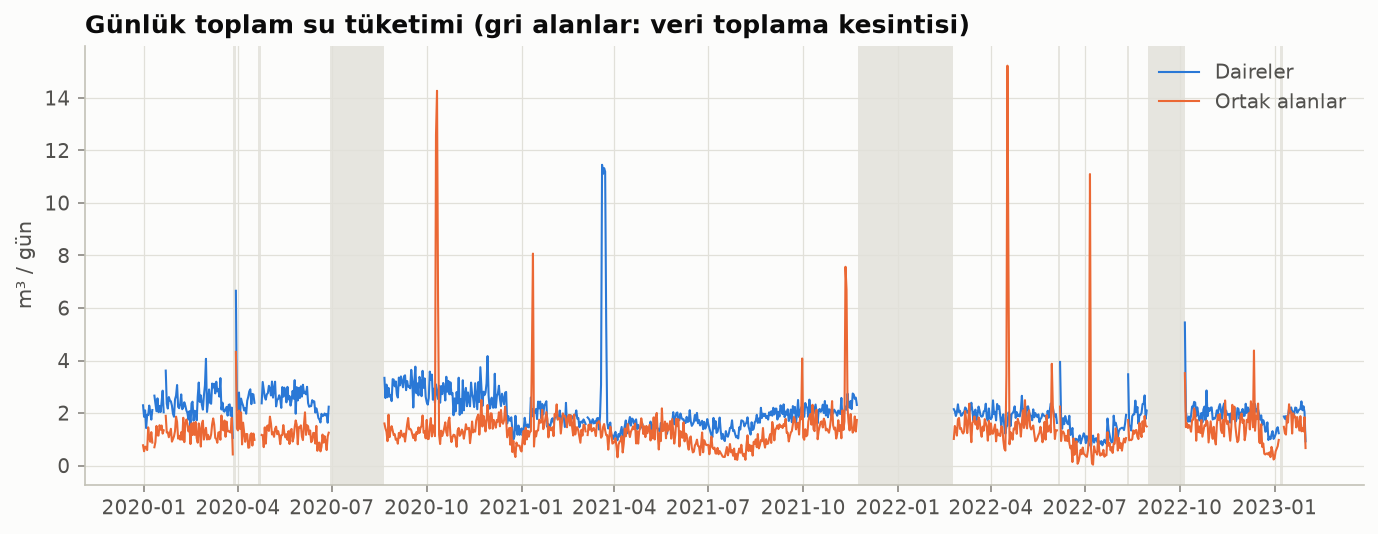

**02_apartment_daily_consumption.png**

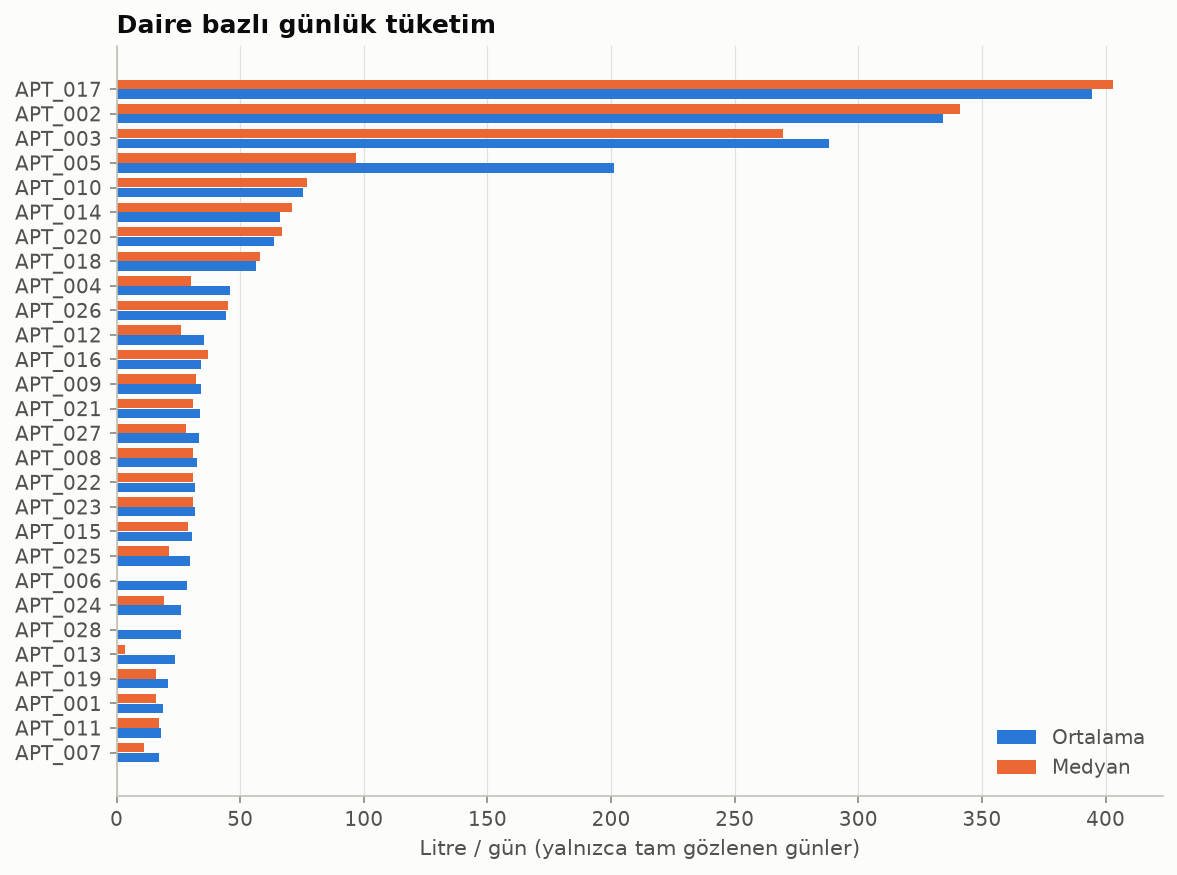

**03_sensor_consumption_top20.png**

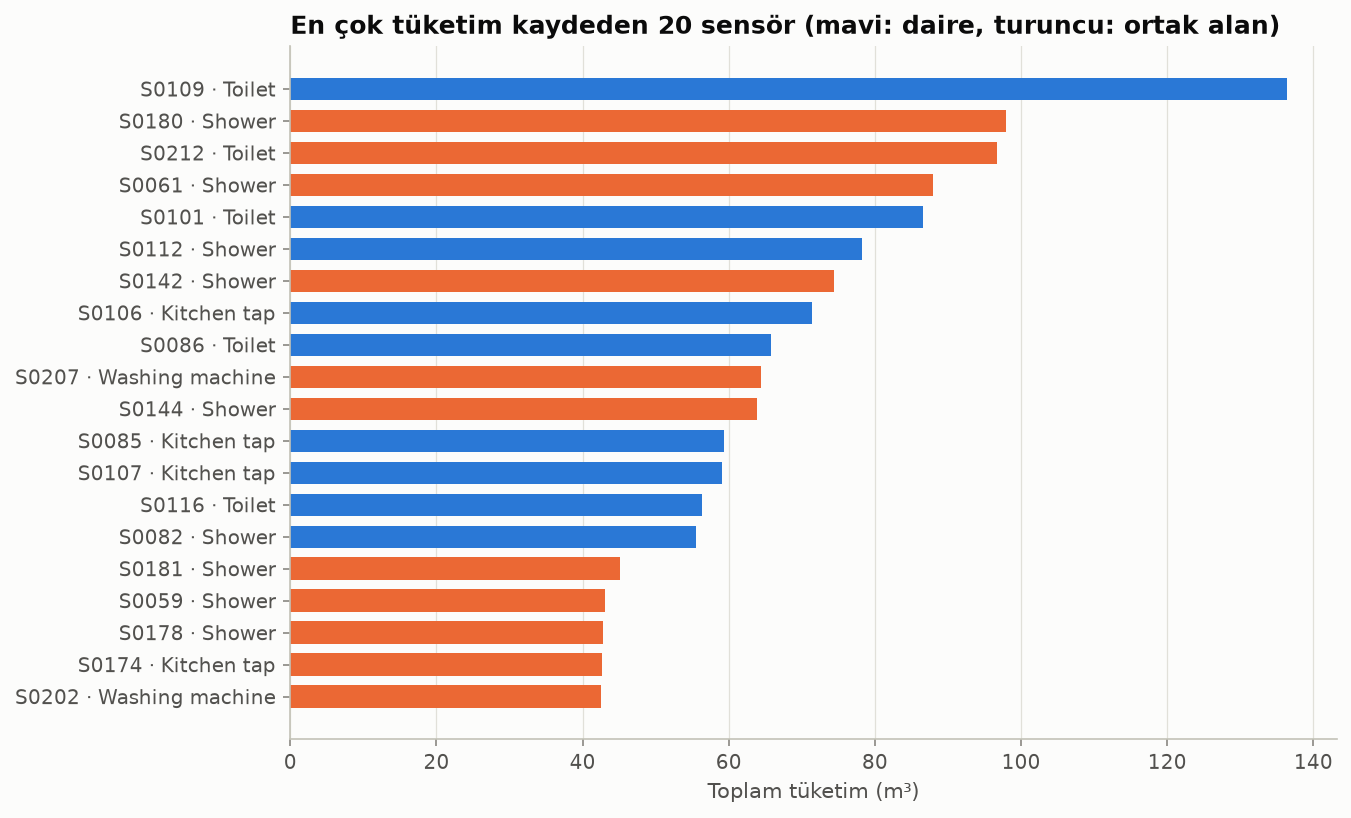

**04_usage_category_consumption.png**

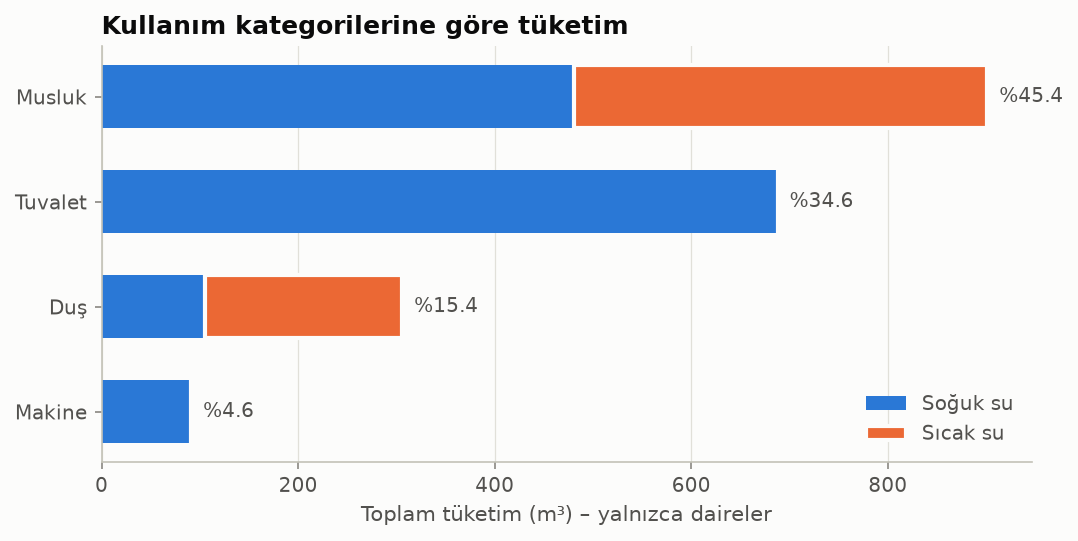

**05_hourly_pattern_weekday_weekend.png**

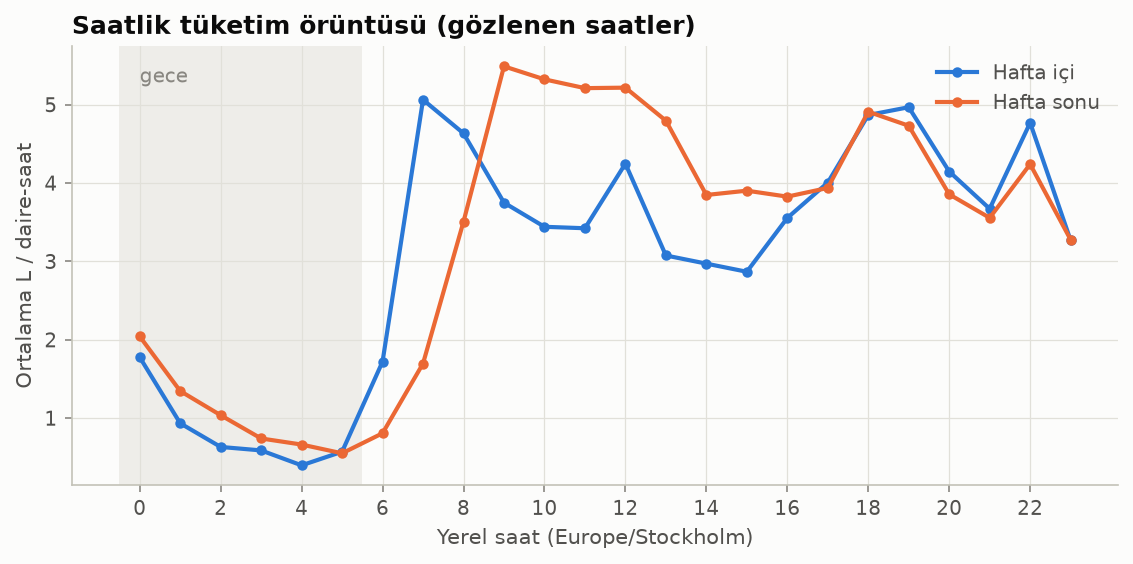

**06_weekly_pattern.png**

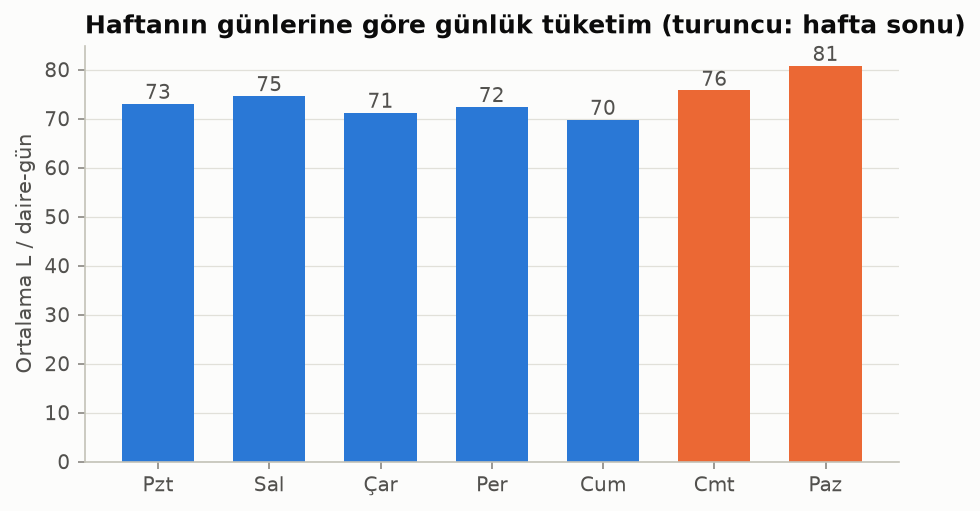

**07_monthly_consumption.png**

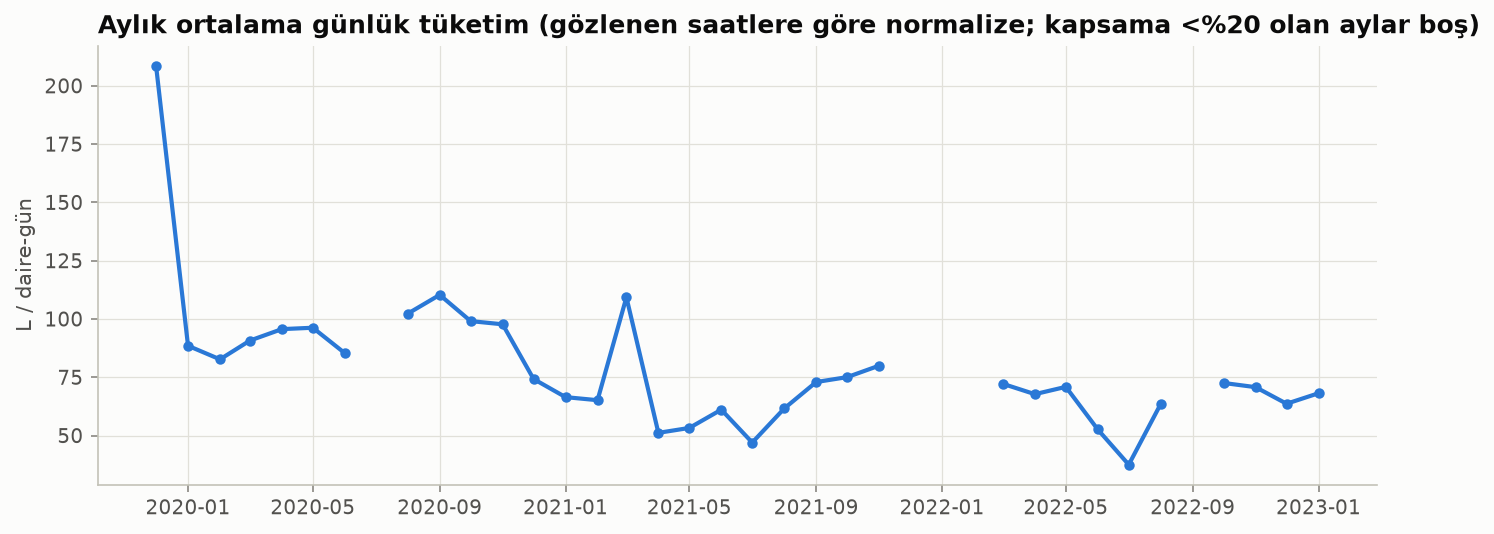

**08_night_consumption_by_apartment.png**

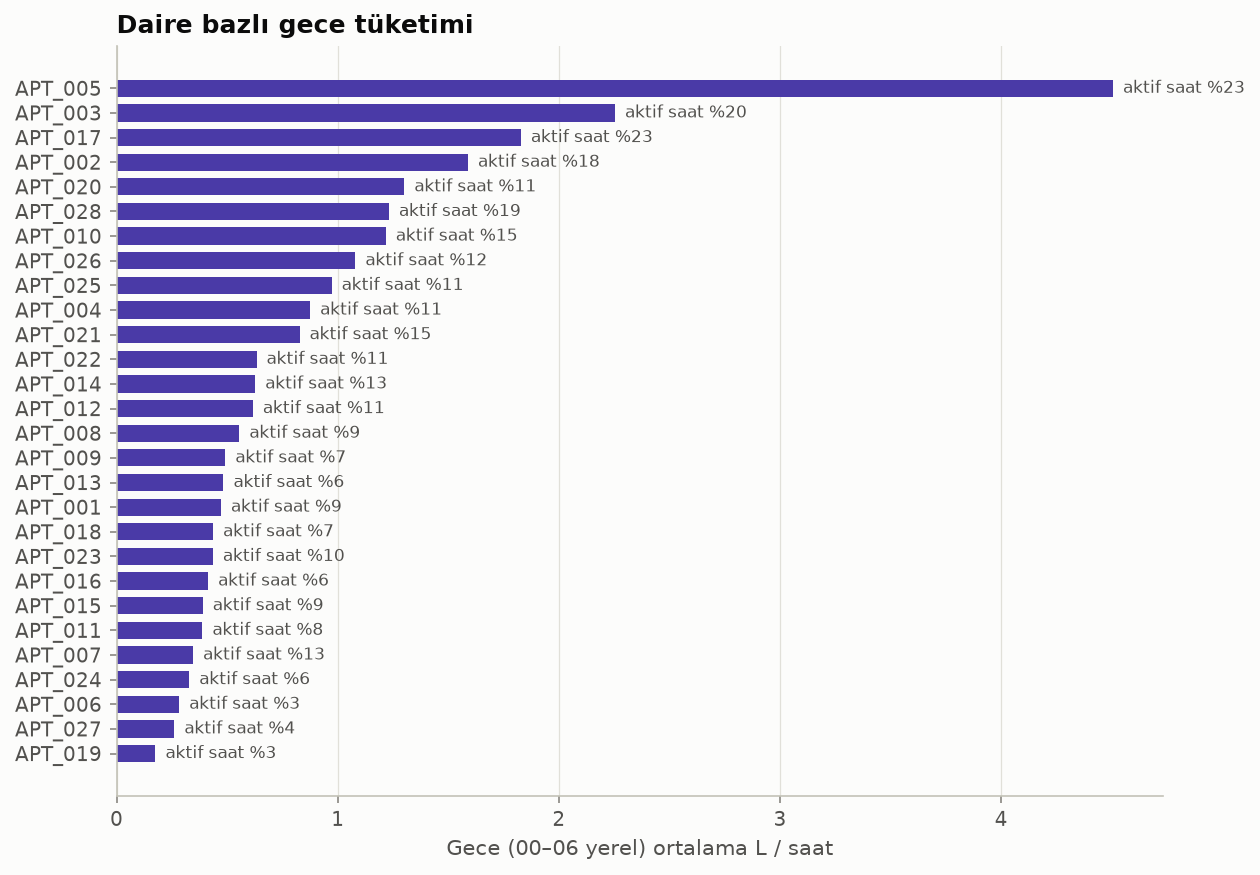

**09_consumption_distribution_outliers.png**

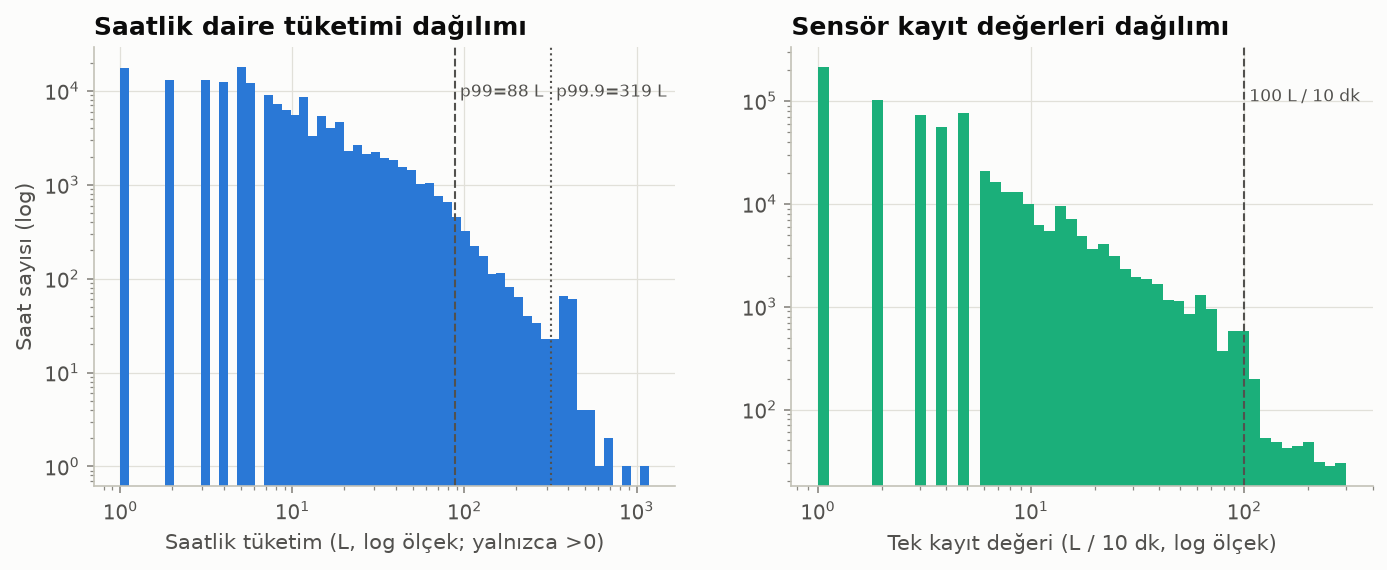

**10_data_coverage_heatmap.png**

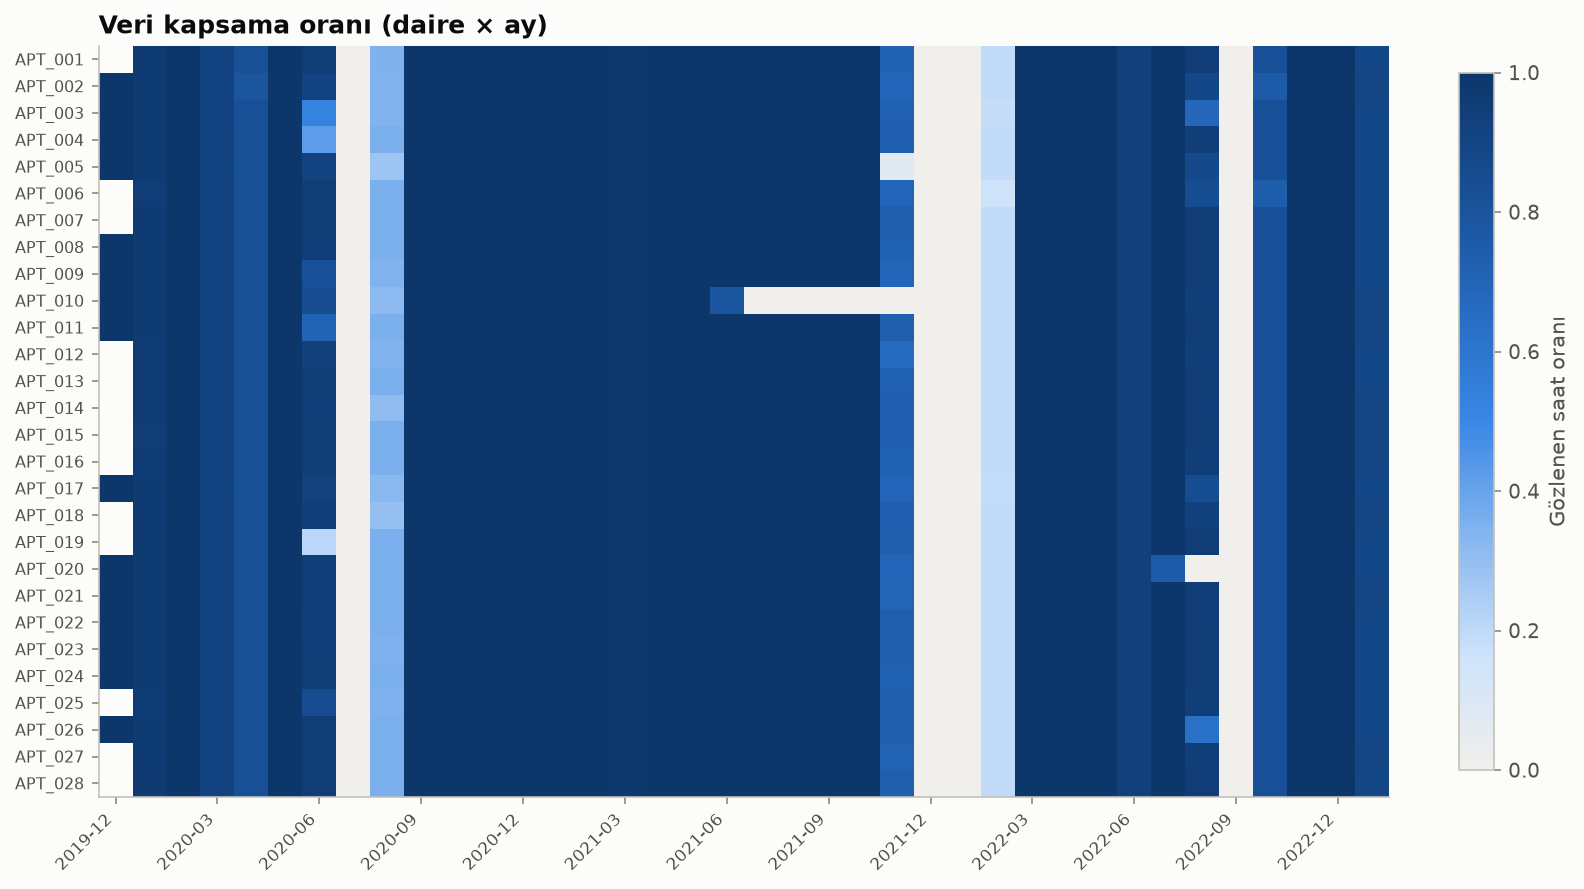

**11_building_outages.png**

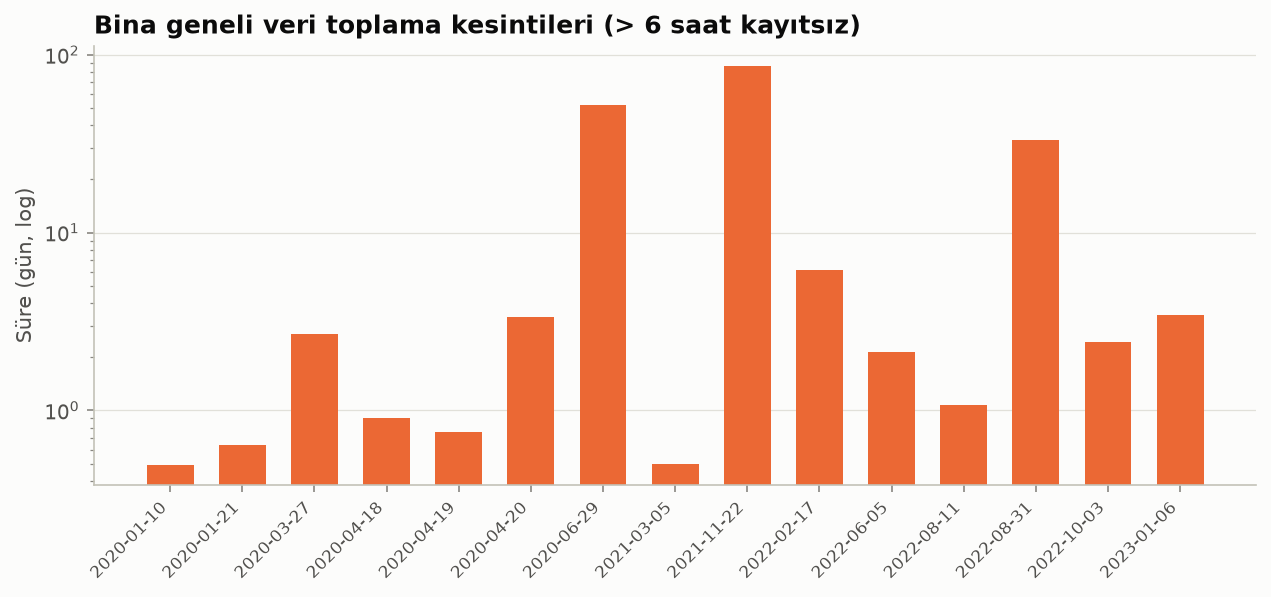

**12_apartment_observation_periods.png**

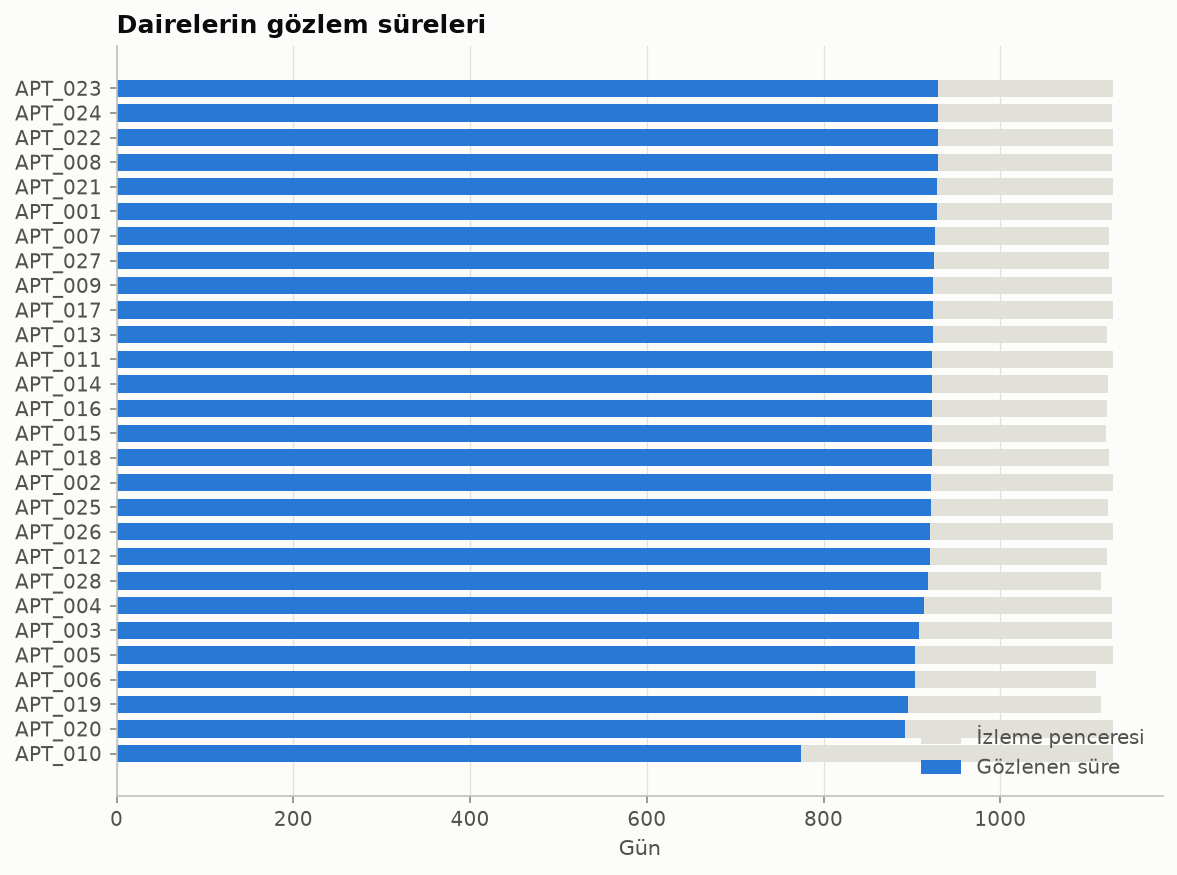

In [5]:
for f in sorted(config.FIGURES_DIR.glob('*.png'))[:12]:
    display(Markdown(f'**{f.name}**'))
    display(Image(filename=str(f), width=820))

## 5. Normal tüketim profili (örnek daire)

In [6]:
prof = json.load(open(config.PROFILES_FILE, encoding='utf-8'))
a = prof['apartments']['APT_011']
print('Profil dönemi:', prof['profile_period_local'])
print(json.dumps({k: a[k] for k in ['daily', 'night', 'continuity']}, ensure_ascii=False, indent=1))

Profil dönemi: {'start': '2020-01-01 00:00:00+01:00', 'end_exclusive': '2021-11-23 00:00:00+01:00'}
{
 "daily": {
  "mean_liters": 19.987,
  "median_liters": 21.0,
  "std_liters": 16.544,
  "p05_liters": 0.0,
  "p95_liters": 47.0,
  "normal_range_liters": [
   0.0,
   47.0
  ],
  "coefficient_of_variation": 0.828,
  "zero_consumption_day_fraction": 0.2832
 },
 "night": {
  "hours_local": [
   0,
   6
  ],
  "mean_liters_per_hour": 0.452,
  "p95_liters_per_hour": 4.0,
  "mean_liters_per_night": 2.693,
  "p95_liters_per_night": 10.0,
  "mean_active_slots_per_night": 0.706,
  "n_full_nights": 623
 },
 "continuity": {
  "description": "Art arda tüketim kaydı olan 10 dk slotların süresi (gerçek akış süresi değildir)",
  "p95_minutes": 10.0,
  "p99_minutes": 20.0,
  "night_p95_minutes": 10.0,
  "night_p99_minutes": 20.0
 }
}


## 6. Model ve değerlendirme sonuçları

In [7]:
meta = json.load(open(config.METADATA_FILE, encoding='utf-8'))
print('Özellikler:', meta['feature_columns'])
print('Hiperparametreler:', meta['hyperparameters'])
print('Global eşikler:', {k: round(v, 4) for k, v in meta['thresholds'].items() if isinstance(v, float)})
display(Markdown(open(config.REPORTS_DIR / 'evaluation_tables.md', encoding='utf-8').read()))

Özellikler: ['hour_sin', 'hour_cos', 'is_weekend', 'log_consumption', 'log_prev_hour', 'log_rolling_3h_sum', 'deviation_from_normal', 'deviation_from_24h', 'deviation_from_7d', 'active_slots', 'log_continuous_activity_min', 'night_log_consumption', 'night_active_slots']
Hiperparametreler: {'bootstrap': False, 'contamination': 'auto', 'max_features': 1.0, 'max_samples': 512, 'n_estimators': 300, 'n_jobs': -1, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Global eşikler: {'suspicious': 0.6061, 'anomalous': 0.6575, 'suspicious_quantile': 0.97, 'anomalous_quantile': 0.995}


# Değerlendirme tabloları (otomatik üretildi)

Eşikler: Şüpheli ≥ 0.6061 (doğrulama q=0.97), Anormal ≥ 0.6575 (q=0.995)

## Gerçek veride alarm oranları

| Küme | Saat | Saat alarm (≥Şüpheli) | Saat Anormal | Gece saat alarm | Daire-gün alarm | Daire-gün Anormal |
|---|---|---|---|---|---|---|
| Eğitim | 403083 | %1.85 | %0.42 | %4.97 | %29.85 | %8.14 |
| Doğrulama | 84140 | %1.74 | %0.29 | %5.02 | %30.07 | %6.16 |
| Test (tümü) | 115202 | %1.57 | %0.34 | %4.51 | %26.51 | %6.95 |
| Test (seçilmiş normal) | 115195 | %1.57 | %0.34 | %4.51 | %26.43 | %6.95 |

## İlk sürüm (yalnızca global eşik) – şeffaflık için

| Küme | Saat alarm | Daire-gün alarm | S1 | S2 | S3 | S4 |
|---|---|---|---|---|---|---|
| Doğrulama | %3.00 | %35.86 | %100.0 | %100.0 | %98.7 | %95.0 |
| Test | %2.70 | %32.21 | %100.0 | %100.0 | %99.3 | %96.0 |

## Sentetik olay yakalama – Doğrulama

| Senaryo | Olay | Yakalama (≥Şüpheli) | Yakalama (Anormal) | Saat bazlı | Medyan max skor |
|---|---|---|---|---|---|
| S1 Gece sürekli akış | 300 | %100.0 | %100.0 | %100.0 | 0.743 |
| S2 Olağandışı yüksek tüketim | 300 | %100.0 | %85.3 | %99.8 | 0.681 |
| S3 Alışılmadık saat | 300 | %97.3 | %79.3 | %97.3 | 0.712 |
| S4 Kısa süreli artış | 300 | %91.7 | %29.3 | %91.7 | 0.638 |

## Sentetik olay yakalama – Test

| Senaryo | Olay | Yakalama (≥Şüpheli) | Yakalama (Anormal) | Saat bazlı | Medyan max skor |
|---|---|---|---|---|---|
| S1 Gece sürekli akış | 300 | %100.0 | %100.0 | %100.0 | 0.745 |
| S2 Olağandışı yüksek tüketim | 300 | %100.0 | %91.3 | %99.8 | 0.679 |
| S3 Alışılmadık saat | 300 | %97.7 | %82.0 | %97.7 | 0.712 |
| S4 Kısa süreli artış | 300 | %93.3 | %30.0 | %93.3 | 0.640 |

## Eşik taraması (test)

| Doğrulama q | Eşik | Test alarm | S1 | S2 | S3 | S4 |
|---|---|---|---|---|---|---|
| 0.9 | 0.5475 | %8.74 | %100.0 | %100.0 | %100.0 | %100.0 |
| 0.93 | 0.5688 | %6.10 | %100.0 | %100.0 | %100.0 | %100.0 |
| 0.95 | 0.5852 | %4.35 | %100.0 | %100.0 | %100.0 | %100.0 |
| 0.97 | 0.6061 | %2.70 | %100.0 | %100.0 | %99.3 | %96.0 |
| 0.98 | 0.6210 | %1.80 | %100.0 | %100.0 | %97.3 | %81.3 |
| 0.99 | 0.6414 | %0.93 | %100.0 | %97.7 | %89.7 | %48.7 |
| 0.995 | 0.6575 | %0.53 | %100.0 | %92.0 | %83.3 | %32.7 |
| 0.999 | 0.6939 | %0.12 | %100.0 | %26.0 | %78.0 | %18.0 |

## Global vs daire bazlı model

| Model | Küme | S1 | S2 | S3 | S4 | Gerçek alarm | Daireler arası alarm std | En yüksek daire alarmı | >%10 daire |
|---|---|---|---|---|---|---|---|---|---|
| global | validation | %100.0 | %100.0 | %98.7 | %95.0 | %3.00 | 4.05 pp | %18.5 | 3 |
| global | test | %100.0 | %100.0 | %99.3 | %96.0 | %2.70 | 3.54 pp | %13.1 | 3 |
| global_adaptive_threshold | validation | %100.0 | %100.0 | %97.3 | %91.7 | %1.74 | 0.90 pp | %3.0 | 0 |
| global_adaptive_threshold | test | %100.0 | %100.0 | %97.7 | %93.3 | %1.57 | 0.87 pp | %3.8 | 0 |
| per_apartment | validation | %100.0 | %100.0 | %98.7 | %98.3 | %3.03 | 0.00 pp | %3.0 | 0 |
| per_apartment | test | %100.0 | %100.0 | %100.0 | %99.7 | %3.05 | 2.11 pp | %10.9 | 1 |

## Hiperparametre duyarlılığı (yalnızca doğrulama)

| n_estimators | max_samples | S1 | S2 | S3 | S4 | Ortalama |
|---|---|---|---|---|---|---|
| 100 | 256 | %100.0 | %100.0 | %91.3 | %81.3 | %93.2 |
| 100 | 512 | %100.0 | %100.0 | %99.0 | %96.7 | %98.9 |
| 100 | 2048 | %100.0 | %100.0 | %99.3 | %98.3 | %99.4 |
| 300 | 256 | %100.0 | %100.0 | %88.3 | %65.3 | %88.4 |
| 300 | 512 | %100.0 | %100.0 | %98.7 | %95.0 | %98.4 |
| 300 | 2048 | %100.0 | %100.0 | %99.3 | %99.3 | %99.7 |

## S1 yakalama – debiye göre (test)

| Debi (L/saat) | Yakalama |
|---|---|
| (5.999, 10.0] | %100.0 |
| (10.0, 15.0] | %100.0 |
| (15.0, 20.0] | %100.0 |
| (20.0, 25.0] | %100.0 |
| (25.0, 30.0] | %100.0 |

## Stres testi – düşük debili gece sızıntısı (1–6 L/saat, test)

Toplam: 300 olay, yakalama (≥Şüpheli) %96.0, Anormal %64.0

| Debi (L/saat) | Yakalama |
|---|---|
| (0.999, 2.0] | %80.0 |
| (2.0, 3.0] | %98.3 |
| (3.0, 4.0] | %100.0 |
| (4.0, 5.0] | %100.0 |
| (5.0, 6.0] | %100.0 |

## Enjeksiyonsuz pencerenin zaten alarm verme oranı (test)

- S1 Gece sürekli akış: %9.3
- S2 Olağandışı yüksek tüketim: %0.7
- S3 Alışılmadık saat: %2.0
- S4 Kısa süreli artış: %2.0


**13_anomaly_score_distribution.png**

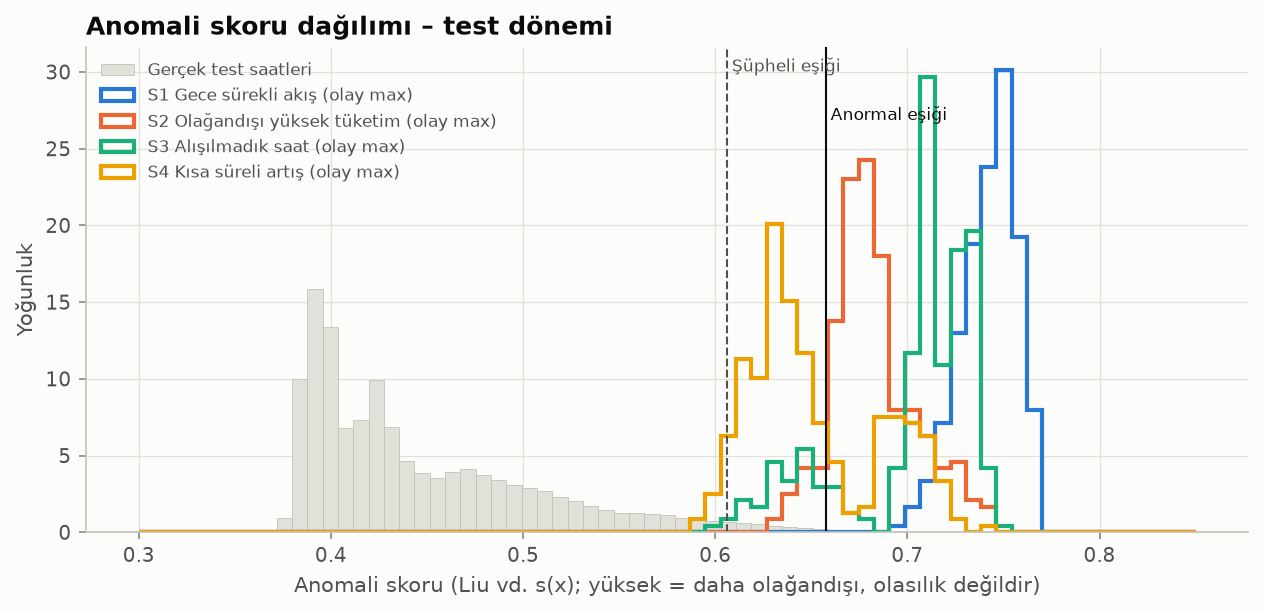

**14_synthetic_detection_by_scenario.png**

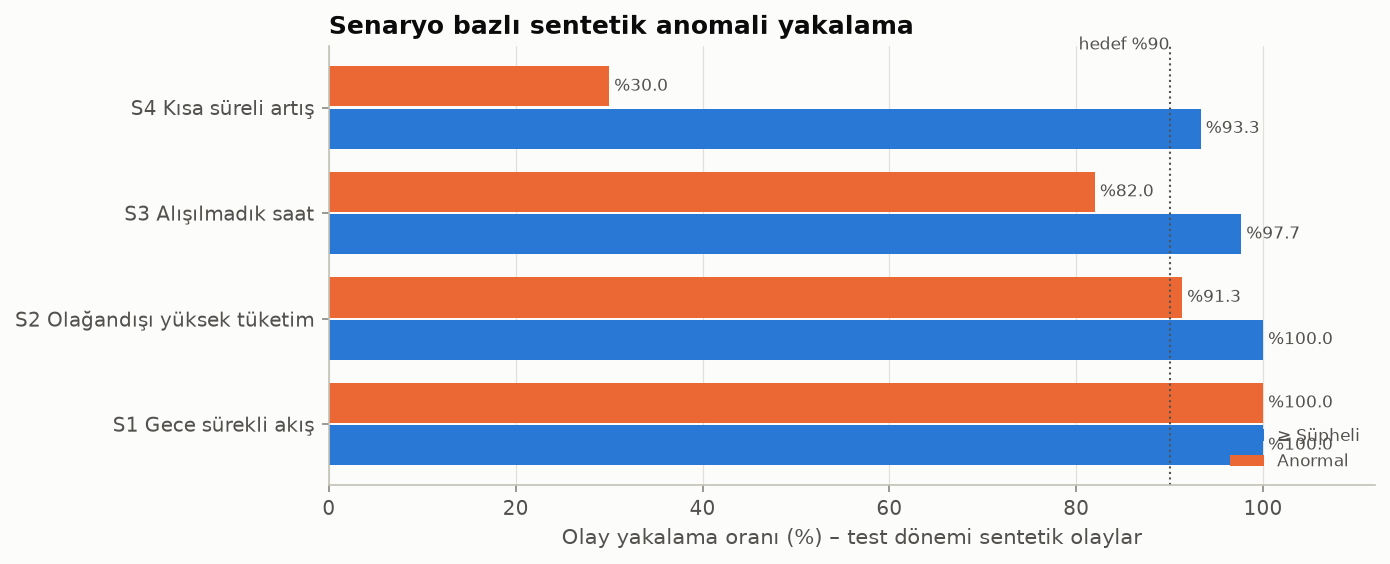

**15_threshold_tradeoff.png**

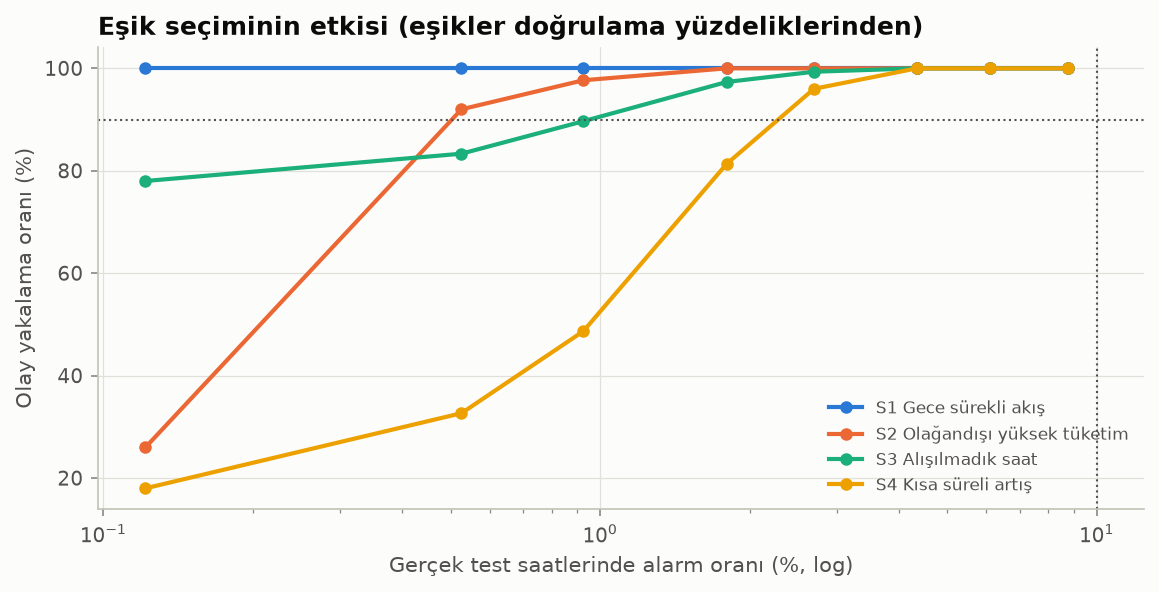

**16_per_apartment_behavior.png**

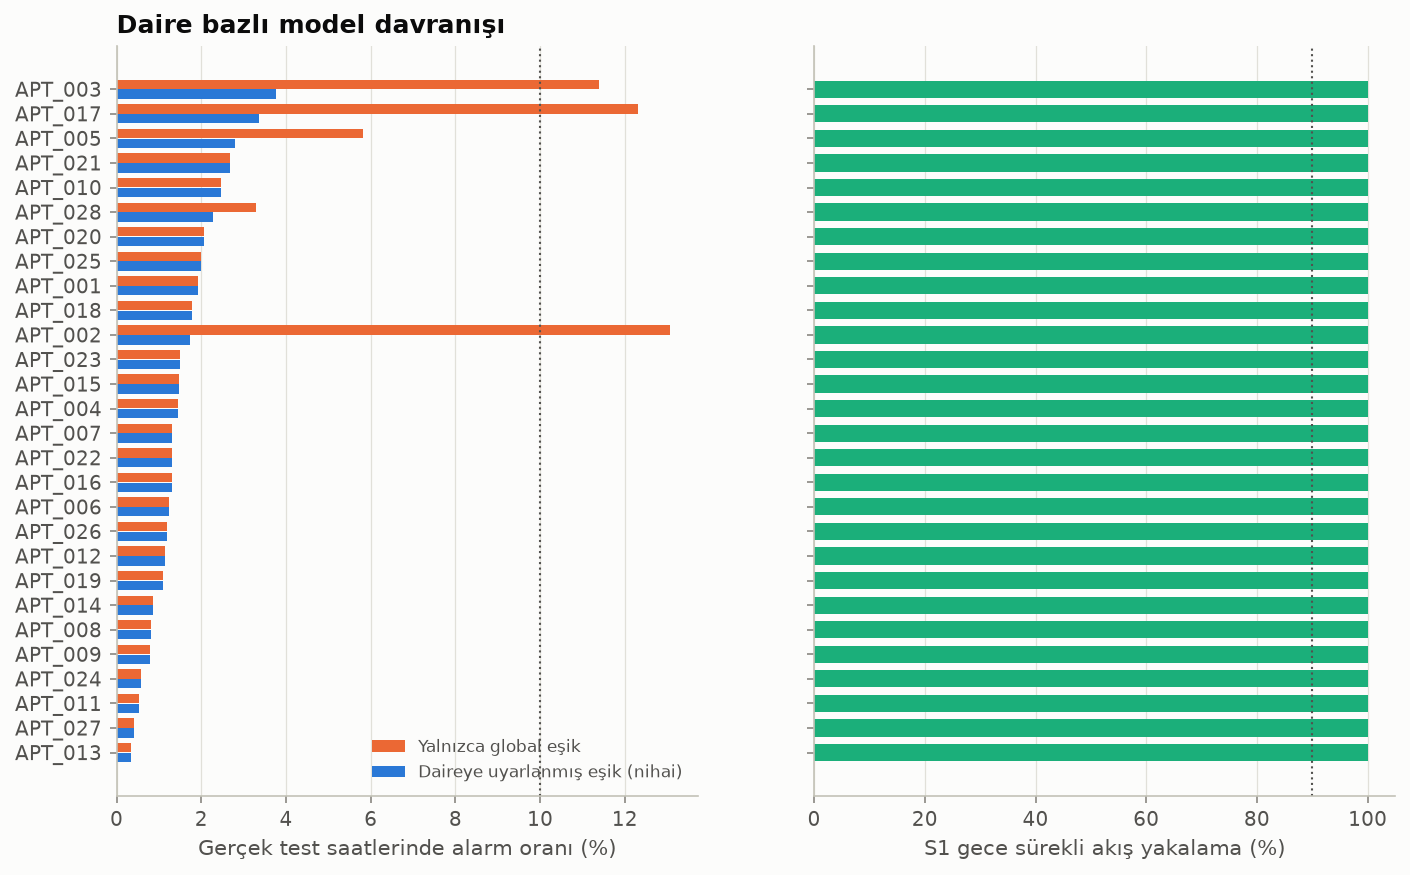

**17_example_night_flow_event.png**

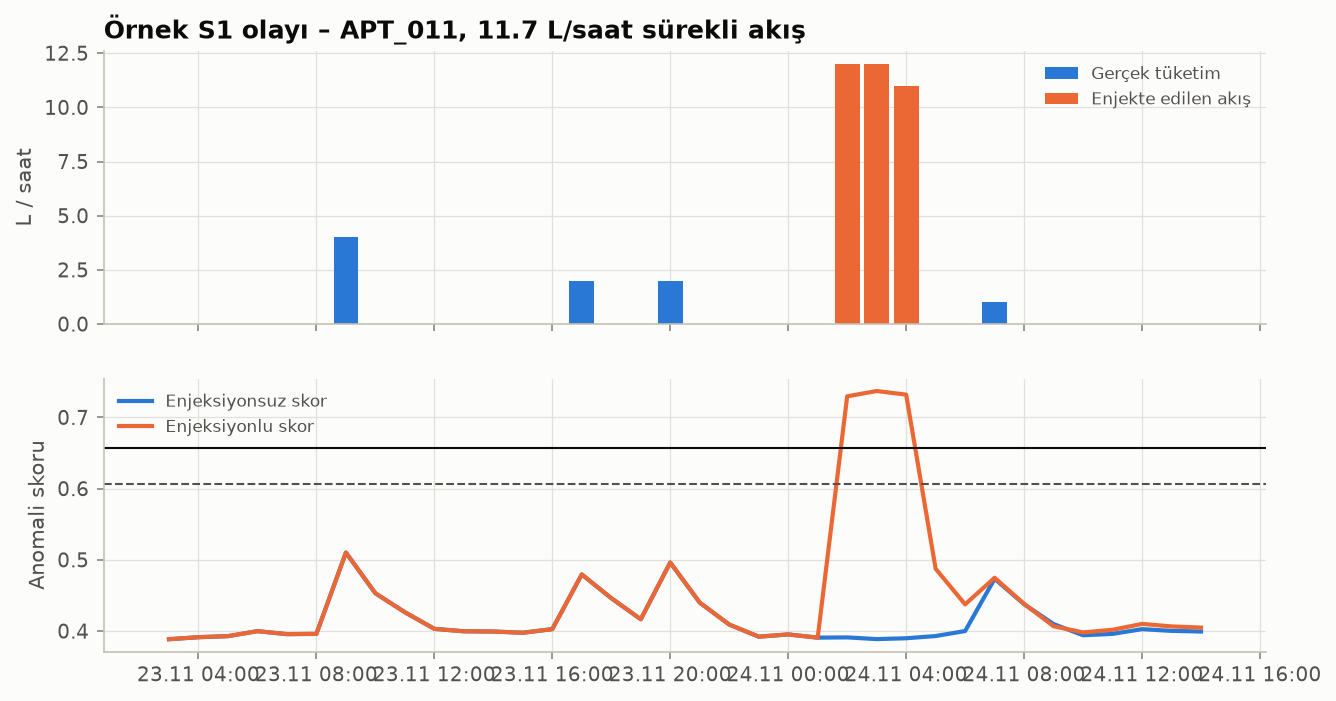

In [8]:
for f in sorted(config.FIGURES_DIR.glob('*.png'))[12:]:
    display(Markdown(f'**{f.name}**'))
    display(Image(filename=str(f), width=820))

## 7. Backend tahmin fonksiyonu örneği

In [9]:
from src.predict import load_detector, predict_anomaly
from src.synthetic_anomalies import make_demo_leak_records
det = load_detector()
rec = pd.read_parquet(config.PROCESSED_DIR / 'apartment_records.parquet')
t = pd.Timestamp('2022-11-24 03:00', tz=config.LOCAL_TZ); h0 = t - pd.Timedelta(days=28)
r = rec[(rec.apartment == 'APT_011') & (rec.timestamp_utc >= h0) & (rec.timestamp_utc < t + pd.Timedelta(hours=1))]
records = [{'timestamp': x.isoformat(), 'consumption_liters': v} for x, v in zip(r.timestamp_utc, r.value_liters)]
normal = predict_anomaly('APT_011', records, t.isoformat(), h0.isoformat(), detector=det)
leak = predict_anomaly('APT_011', records + make_demo_leak_records(t - pd.Timedelta(hours=2), 3, 18), t.isoformat(), h0.isoformat(), detector=det)
pd.DataFrame([normal, leak])[['timestamp_local', 'consumption_liters', 'status', 'anomaly_score', 'message']]

,timestamp_local,consumption_liters,status,anomaly_score,message
0,2022-11-24T03:00:00+01:00,0.0,Normal,0.3887,Su tüketimi dairenin normal tüketim aralığında.
1,2022-11-24T03:00:00+01:00,18.0,Anormal,0.7486,Gece saatlerinde olağandışı su tüketimi tespit...
